This notebook was run on Google Colab (GPU L4) and downloaded from it. Shared Colab version: https://colab.research.google.com/drive/1CqfzOB5Imr6vB0NkorWxouEI6q_QdW7O?usp=sharing

In [1]:
from google.colab import drive
drive.mount("/content/drive")
DRIVE = "/content/drive/MyDrive/DPL_Final"
RAW = f"{DRIVE}/data/raw"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!git clone https://github.com/iLogicus/image-to-3d-transformer.git /content/project
%cd /content/project
!pip install -r requirements.txt

fatal: destination path '/content/project' already exists and is not an empty directory.
/content/project


In [3]:
!mkdir -p data/raw
!ln -s $DRIVE/data/processed data/processed
!ln -s $DRIVE/outputs outputs

In [4]:
!nvidia-smi

Mon Nov  2 21:23:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   34C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
import sys
sys.path.insert(0, "src")
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import DataLoader
from cross_eval import choose_axes, points_to_voxels
from dataset.shapenet import CLASS_NAMES, VoxelDataset, image_path, load_points, read_binvox, read_split, retr_transform, voxel_path
from eval_pix3d import choose_rotation, load_image
from models.retr import load_trained
from utils import load_config

In [6]:
!unzip -q $RAW/rgb2point/ShapeNetRendering.zip "02691156/*" "02958343/*" -d data/raw/ShapeNetRendering
!unzip -q $RAW/r2n2_hf/r2n2_shapenet_dataset_full.zip "*/ShapeNetRendering/03001627/*" "*/ShapeNetVoxels/02691156/*" "*/ShapeNetVoxels/02958343/*" "*/ShapeNetVoxels/03001627/*" -d /content/hf
!mv /content/hf/*/r2n2/ShapeNetRendering/03001627 data/raw/ShapeNetRendering/
!mv /content/hf/*/r2n2/ShapeNetVoxels data/raw/ShapeNetVox32
!unzip -q $RAW/3dlmnet/ShapeNet_pointclouds.zip "*/02691156/*" "*/02958343/*" "*/03001627/*" -d data/raw
!ls data/raw/*

data/raw/ShapeNet_pointclouds:
02691156  02958343  03001627

data/raw/ShapeNetRendering:
02691156  02958343  03001627

data/raw/ShapeNetVox32:
02691156  02958343  03001627


In [7]:
!ln -s $RAW/pix3d data/raw/pix3d
!ln -s $RAW/3dlmnet/pix3d_pointclouds data/raw/pix3d_pointclouds
!ls data/raw/pix3d/img/chair | wc -l

3839


In [8]:
classes = ["car", "airplane", "chair"]
for stage in ["train", "val", "test"]:
    objects = read_split("data/ShapeNet.json", classes, stage)
    for class_id, name in CLASS_NAMES.items():
        count = len([c for c, o in objects if c == class_id])
        print(stage, name, count)

train airplane 2831
train car 5245
train chair 4744
val airplane 404
val car 749
val chair 677
test airplane 810
test car 1501
test chair 1357


In [9]:
cfg = load_config("configs/retr_s.yaml")
rows = []
for class_id, name in CLASS_NAMES.items():
    objects = read_split(cfg["data"]["split"], [name], "train")[:500]
    folder = os.path.dirname(image_path(cfg["data"], *objects[0], 0))
    views = len([f for f in os.listdir(folder) if f.endswith(".png")])
    voxels = np.stack([read_binvox(voxel_path(cfg["data"], *o)) for o in objects])
    rows.append([name, views, Image.open(image_path(cfg["data"], *objects[0], 0)).size, voxels.mean() * 100, voxels.sum((1, 2, 3)).mean()])
pd.DataFrame(rows, columns=["class", "views per object", "image size", "occupied voxels %", "occupied voxels"]).round(2)

,class,views per object,image size,occupied voxels %,occupied voxels
0,airplane,24,"(137, 137)",2.02,661.340027
1,car,24,"(137, 137)",9.22,3022.709961
2,chair,10,"(137, 137)",11.89,3896.350098


[test] objects: 3668, samples: 3668, skipped (missing files): 0


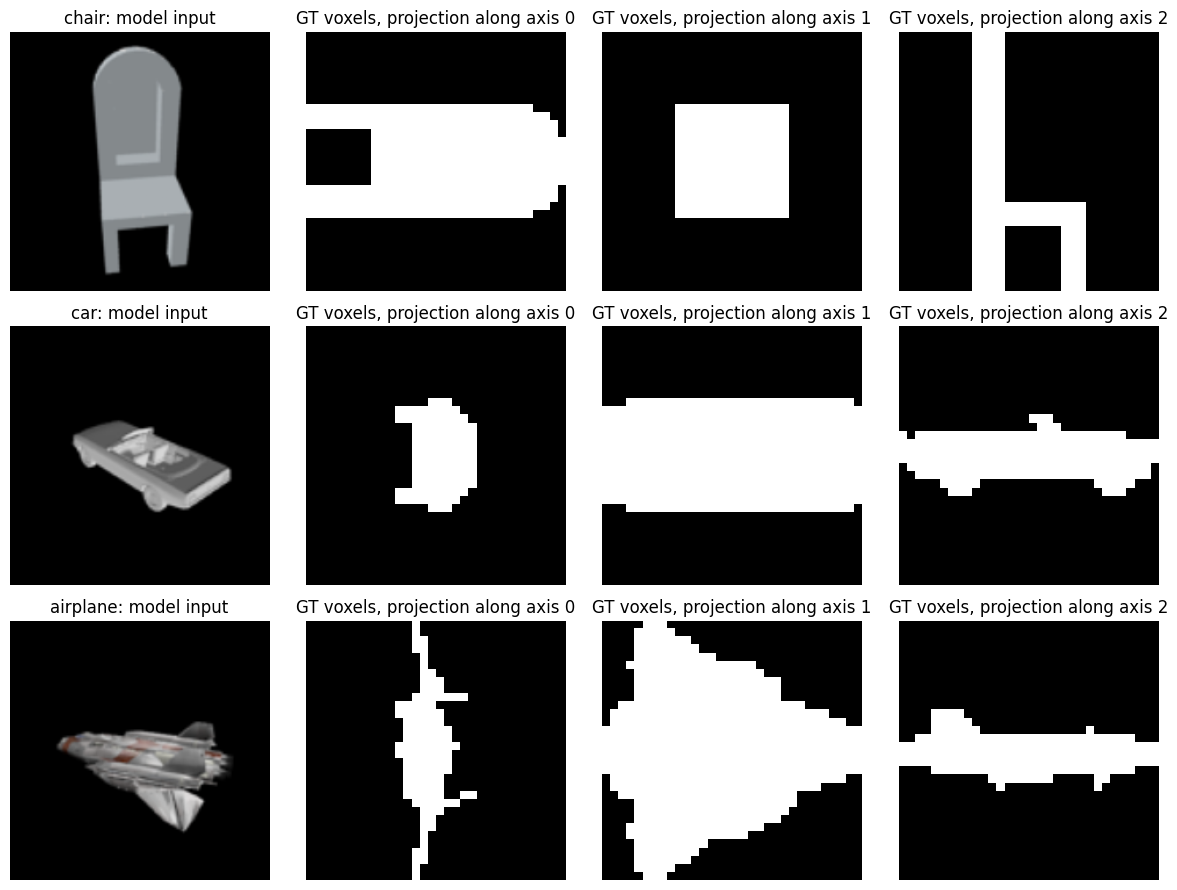

In [10]:
test_set = VoxelDataset(cfg["data"], "test")
first = {class_id: i for i, (class_id, obj) in reversed(list(enumerate(test_set.objects)))}
fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for row, (class_id, i) in enumerate(first.items()):
    image, voxels, _ = test_set[i]
    ax[row, 0].imshow((image.permute(1, 2, 0) * 0.5 + 0.5).numpy())
    ax[row, 0].set_title(f"{CLASS_NAMES[class_id]}: model input")
    for axis in range(3):
        ax[row, axis + 1].imshow(voxels.amax(axis).T.numpy(), origin="lower", cmap="gray")
        ax[row, axis + 1].set_title(f"GT voxels, projection along axis {axis}")
    for a in ax[row]:
        a.axis("off")
plt.tight_layout()
plt.show()

In [11]:
val_objects = read_split(cfg["data"]["split"], classes, "val")[::10]
val_voxels = torch.stack([torch.from_numpy(read_binvox(voxel_path(cfg["data"], *o)) > 0.5) for o in val_objects])
axes = choose_axes(val_voxels, load_points(cfg["data"], val_objects))

Chosen axes (voxel -> point cloud):
 [[ 0. -1.  0.]
 [ 0.  0. -1.]
 [ 1.  0.  0.]] 
GT voxels vs GT points CD x100: 3.907


In [12]:
!python src/train_retr.py --config configs/retr_s.yaml

Training already finished, log:
Epoch 1/50  loss 0.6724  val IoU 0.5206  lr 1.0e-04  50s
Epoch 2/50  loss 0.6326  val IoU 0.5653  lr 1.0e-04  51s
Epoch 3/50  loss 0.6239  val IoU 0.5742  lr 1.0e-04  51s
Epoch 4/50  loss 0.6170  val IoU 0.5846  lr 1.0e-04  49s
Epoch 5/50  loss 0.6132  val IoU 0.6044  lr 1.0e-04  50s
Epoch 6/50  loss 0.6101  val IoU 0.6077  lr 1.0e-04  50s
Epoch 7/50  loss 0.6077  val IoU 0.6129  lr 1.0e-04  50s
Epoch 8/50  loss 0.6053  val IoU 0.6125  lr 1.0e-04  51s
Epoch 9/50  loss 0.6031  val IoU 0.6126  lr 1.0e-04  50s
Epoch 10/50  loss 0.6017  val IoU 0.6193  lr 1.0e-04  51s
Epoch 11/50  loss 0.6005  val IoU 0.6085  lr 1.0e-04  50s
Epoch 12/50  loss 0.5989  val IoU 0.6217  lr 1.0e-04  50s
Epoch 13/50  loss 0.5978  val IoU 0.6329  lr 1.0e-04  50s
Epoch 14/50  loss 0.5967  val IoU 0.6367  lr 1.0e-04  51s
Epoch 15/50  loss 0.5952  val IoU 0.6350  lr 1.0e-04  51s
Epoch 16/50  loss 0.5940  val IoU 0.6246  lr 1.0e-04  50s
Epoch 17/50  loss 0.5933  val IoU 0.6379  lr 1.0e

In [13]:
!python src/evaluate_retr.py --config configs/retr_s.yaml --ckpt outputs/baseline2/base_retr_s/best.pt --name test_full
!python src/evaluate_retr.py --config configs/retr_s.yaml --ckpt outputs/baseline2/base_retr_s/best.pt --split train --name train_full

Checkpoint epoch: 49
[test] objects: 3668, samples: 3668, skipped (missing files): 0
class          IoU
airplane    0.6486
car         0.8415
chair       0.5425
mean        0.6775
Params: 10.34M
Inference: 17.0 ms/image, GPU memory 0.08 GB
Checkpoint epoch: 49
[train] objects: 12820, samples: 12820, skipped (missing files): 0
class          IoU
airplane    0.6795
car         0.8512
chair       0.6003
mean        0.7103
Params: 10.34M
Inference: 17.0 ms/image, GPU memory 0.08 GB


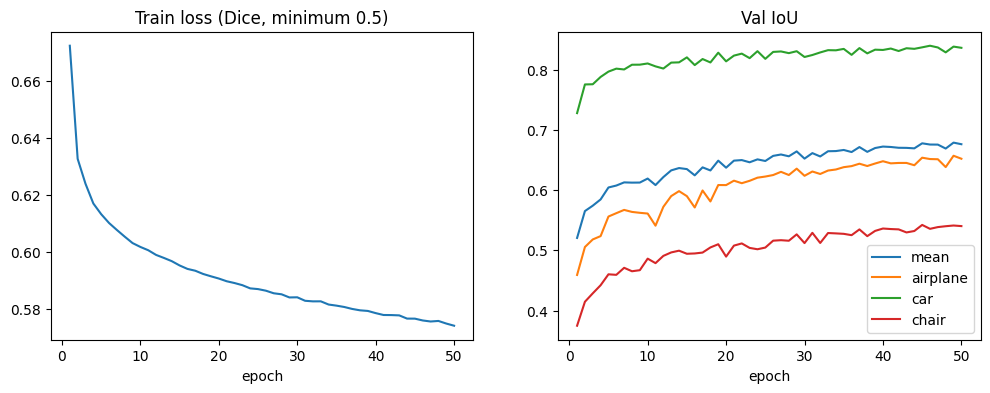

In [14]:
log = [json.loads(line) for line in open("outputs/baseline2/base_retr_s/log.jsonl")]
epochs = [r["epoch"] for r in log]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epochs, [r["train_loss"] for r in log])
ax[0].set_title("Train loss (Dice, minimum 0.5)")
ax[1].plot(epochs, [r["val_iou"] for r in log], label="mean")
for class_id, name in CLASS_NAMES.items():
    ax[1].plot(epochs, [r["val_per_class"][class_id]["iou"] for r in log], label=name)
ax[1].set_title("Val IoU")
ax[1].legend()
for a in ax:
    a.set_xlabel("epoch")
plt.show()

In [15]:
paper = {"airplane": 0.696, "car": 0.858, "chair": 0.579}
test = json.load(open("outputs/baseline2/base_retr_s/test_full.json"))
train = json.load(open("outputs/baseline2/base_retr_s/train_full.json"))
rows = [[name, paper[name], test[class_id]["iou"], train[class_id]["iou"]] for class_id, name in CLASS_NAMES.items()]
rows.append(["mean", np.mean(list(paper.values())), test["mean"]["iou"], train["mean"]["iou"]])
pd.DataFrame(rows, columns=["class", "Paper IoU", "Ours test IoU", "Ours train IoU"]).round(4)

,class,Paper IoU,Ours test IoU,Ours train IoU
0,airplane,0.696,0.6486,0.6795
1,car,0.858,0.8415,0.8512
2,chair,0.579,0.5425,0.6003
3,mean,0.711,0.6775,0.7103


In [16]:
!python src/analyze_retr.py --config configs/retr_s.yaml --ckpt outputs/baseline2/base_retr_s/best.pt
!python src/analyze_retr.py --config configs/retr_s.yaml --ckpt outputs/baseline2/base_retr_s/best.pt --split val

[test] objects: 3668, samples: 69034, skipped (missing files): 0
100% 540/540 [01:07<00:00,  7.96it/s]
Saved 69034 rows to outputs/baseline2/base_retr_s/analysis_test.csv
[val] objects: 1830, samples: 34442, skipped (missing files): 0
100% 270/270 [00:34<00:00,  7.85it/s]
Saved 34442 rows to outputs/baseline2/base_retr_s/analysis_val.csv


In [17]:
df = pd.read_csv("outputs/baseline2/base_retr_s/analysis_test.csv")
print("Elevation range:", df["elevation"].min(), "-", df["elevation"].max())
df["azimuth_bin"] = (df["azimuth"] // 45) * 45
print(df.pivot_table(index="class", columns="azimuth_bin", values="iou_0.5").round(3))

Elevation range: 25.0000745815 - 29.9999099786
azimuth_bin  0.0    45.0   90.0   135.0  180.0  225.0  270.0  315.0
class                                                              
airplane     0.638  0.661  0.651  0.627  0.635  0.670  0.665  0.627
car          0.836  0.851  0.846  0.837  0.839  0.844  0.848  0.837
chair        0.534  0.561  0.561  0.536  0.519  0.560  0.558  0.527


In [18]:
per_object = df.groupby(["class", "object"])["iou_0.5"].mean()
print("Std of IoU between objects:", per_object.groupby("class").std().round(3).to_dict())
print("Std of IoU between views of one object:", df.groupby(["class", "object"])["iou_0.5"].std().groupby("class").mean().round(3).to_dict())

Std of IoU between objects: {'airplane': 0.169, 'car': 0.089, 'chair': 0.16}
Std of IoU between views of one object: {'airplane': 0.051, 'car': 0.026, 'chair': 0.058}


In [19]:
model = load_trained(cfg, "cuda")
pred, gt = [], []
with torch.no_grad():
    for images, voxels, _ in DataLoader(test_set, batch_size=64, num_workers=8):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            pred.append((torch.sigmoid(model(images.cuda()).float()) > 0.5).cpu())
        gt.append(voxels > 0.5)
pred, gt = torch.cat(pred), torch.cat(gt)
class_of = np.array([c for c, o in test_set.objects])
pair_iou = lambda a, b: ((a & b).flatten(1).sum(1) / (a | b).flatten(1).sum(1)).mean().item()

for class_id, name in CLASS_NAMES.items():
    idx = np.where(class_of == class_id)[0]
    other = np.roll(idx, 1)
    mean_shape = np.mean([read_binvox(voxel_path(cfg["data"], *o)) for o in read_split(cfg["data"]["split"], [name], "train")], axis=0)
    template = torch.from_numpy(mean_shape > 0.3)[None].expand(len(idx), -1, -1, -1)
    print(name, "IoU between 2 different objects: predictions", round(pair_iou(pred[idx], pred[other]), 3),
          "| ground truth", round(pair_iou(gt[idx], gt[other]), 3),
          "| mean train shape as prediction", round(pair_iou(template, gt[idx]), 3))

airplane IoU between 2 different objects: predictions 0.354 | ground truth 0.3 | mean train shape as prediction 0.433
car IoU between 2 different objects: predictions 0.71 | ground truth 0.625 | mean train shape as prediction 0.725
chair IoU between 2 different objects: predictions 0.169 | ground truth 0.13 | mean train shape as prediction 0.235


In [20]:
val = pd.read_csv("outputs/baseline2/base_retr_s/analysis_val.csv")
val.groupby("class")[["iou_0.2", "iou_0.3", "iou_0.4", "iou_0.5"]].mean().round(4)

,iou_0.2,iou_0.3,iou_0.4,iou_0.5
class,,,,
airplane,0.6237,0.6467,0.6551,0.6538
car,0.8214,0.8353,0.8408,0.8402
chair,0.5070,0.5307,0.5414,0.5424


In [21]:
df.groupby("class")[["iou_0.5", "precision", "recall", "gt_voxels", "pred_voxels"]].mean().round(3)

,iou_0.5,precision,recall,gt_voxels,pred_voxels
class,,,,,
airplane,0.647,0.780,0.770,659.247,654.587
car,0.842,0.912,0.914,3010.797,2993.279
chair,0.544,0.662,0.735,3801.508,4190.529


In [22]:
df["size_quartile"] = df.groupby("class")["gt_voxels"].transform(lambda s: pd.qcut(s, 4, labels=False))
df.pivot_table(index="class", columns="size_quartile", values=["iou_0.5", "precision", "recall"]).round(3)

iou_0.5                      precision                       \
size_quartile       0      1      2      3         0      1      2      3   
class                                                                       
airplane        0.598  0.685  0.705  0.601     0.720  0.806  0.831  0.764   
car             0.805  0.870  0.873  0.821     0.860  0.921  0.940  0.929   
chair           0.471  0.532  0.536  0.637     0.576  0.652  0.662  0.758   

              recall                       
size_quartile      0      1      2      3  
class                                      
airplane       0.752  0.802  0.807  0.721  
car            0.924  0.939  0.922  0.871  
chair          0.696  0.723  0.720  0.799

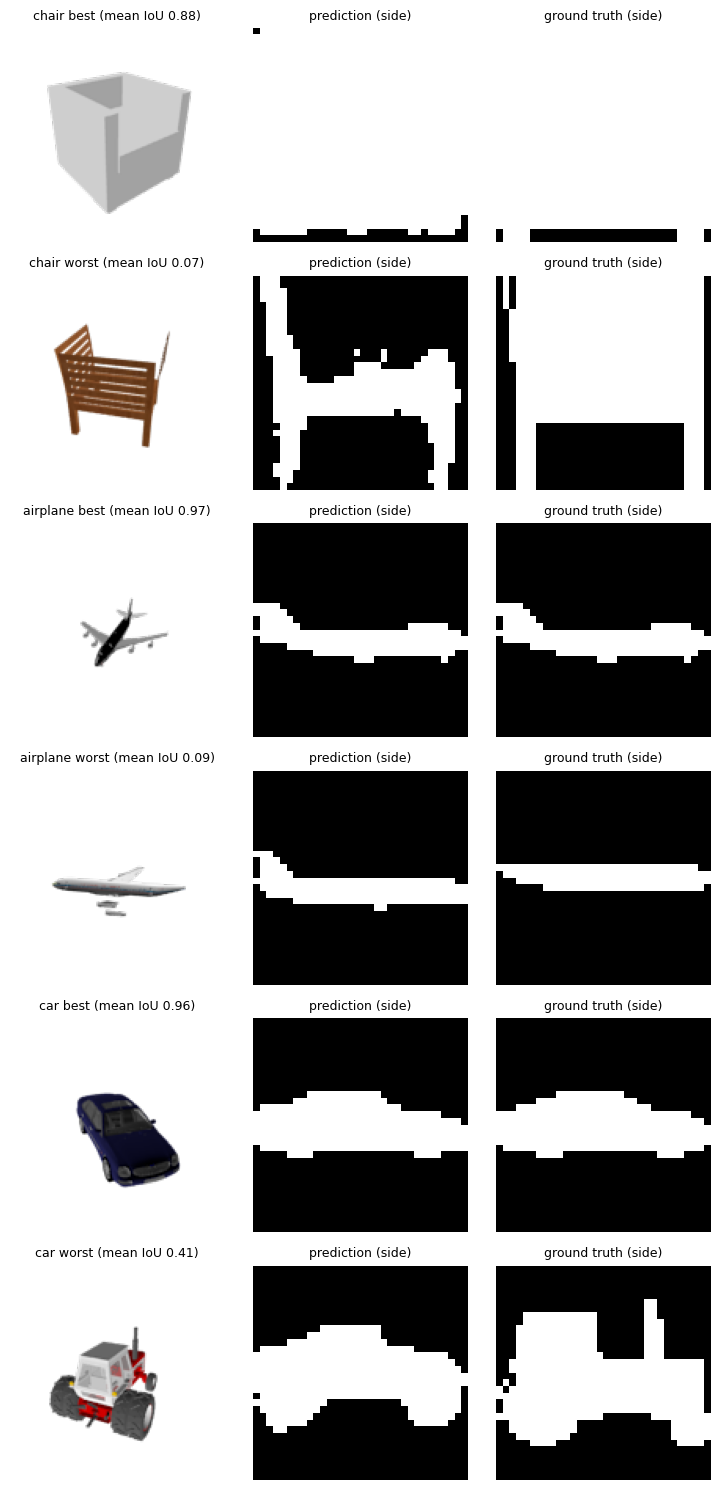

In [23]:
examples = []
for name in ["chair", "airplane", "car"]:
    objects = per_object[name].sort_values()
    examples.append((name, objects.index[-1], "best"))
    examples.append((name, objects.index[0], "worst"))

position = {obj: i for i, (c, obj) in enumerate(test_set.objects)}
fig, ax = plt.subplots(len(examples), 3, figsize=(7.5, 2.5 * len(examples)))
for row, (name, obj, label) in enumerate(examples):
    i = position[obj]
    ax[row, 0].imshow(Image.open(image_path(cfg["data"], test_set.objects[i][0], obj, 0)))
    ax[row, 0].set_title(f"{name} {label} (mean IoU {per_object[name][obj]:.2f})", fontsize=9)
    ax[row, 1].imshow(pred[i].amax(2).T.numpy(), origin="lower", cmap="gray")
    ax[row, 1].set_title("prediction (side)", fontsize=9)
    ax[row, 2].imshow(gt[i].amax(2).T.numpy(), origin="lower", cmap="gray")
    ax[row, 2].set_title("ground truth (side)", fontsize=9)
    for a in ax[row]:
        a.axis("off")
plt.tight_layout()
plt.show()

In [24]:
!python src/train_retr.py --config configs/retr_v1_dinov2.yaml

Training already finished, log:
Epoch 1/50  loss 0.6750  val IoU 0.5296  lr 1.0e-04  54s
Epoch 2/50  loss 0.6355  val IoU 0.5614  lr 1.0e-04  54s
Epoch 3/50  loss 0.6250  val IoU 0.5723  lr 1.0e-04  54s
Epoch 4/50  loss 0.6177  val IoU 0.5936  lr 1.0e-04  53s
Epoch 5/50  loss 0.6127  val IoU 0.6055  lr 1.0e-04  53s
Epoch 6/50  loss 0.6095  val IoU 0.6132  lr 1.0e-04  53s
Epoch 7/50  loss 0.6064  val IoU 0.6121  lr 1.0e-04  53s
Epoch 8/50  loss 0.6046  val IoU 0.6208  lr 1.0e-04  54s
Epoch 9/50  loss 0.6020  val IoU 0.6246  lr 1.0e-04  53s
Epoch 10/50  loss 0.6005  val IoU 0.6125  lr 1.0e-04  53s
Epoch 11/50  loss 0.5986  val IoU 0.6272  lr 1.0e-04  52s
Epoch 12/50  loss 0.5974  val IoU 0.6295  lr 1.0e-04  53s
Epoch 13/50  loss 0.5960  val IoU 0.6328  lr 1.0e-04  54s
Epoch 14/50  loss 0.5946  val IoU 0.6405  lr 1.0e-04  53s
Epoch 15/50  loss 0.5932  val IoU 0.6406  lr 1.0e-04  53s
Epoch 16/50  loss 0.5923  val IoU 0.6393  lr 1.0e-04  54s
Epoch 17/50  loss 0.5910  val IoU 0.6369  lr 1.0e

In [25]:
!python src/evaluate_retr.py --config configs/retr_v1_dinov2.yaml --ckpt outputs/baseline2/v1_dinov2/best.pt --name test_full
!python src/evaluate_retr.py --config configs/retr_v1_dinov2.yaml --ckpt outputs/baseline2/v1_dinov2/best.pt --split train --name train_full

Checkpoint epoch: 50
[test] objects: 3668, samples: 3668, skipped (missing files): 0
class          IoU
airplane    0.6569
car         0.8502
chair       0.5519
mean        0.6863
Params: 26.52M
Inference: 18.3 ms/image, GPU memory 0.18 GB
Checkpoint epoch: 50
[train] objects: 12820, samples: 12820, skipped (missing files): 0
class          IoU
airplane    0.6928
car         0.8594
chair       0.6097
mean        0.7206
Params: 26.52M
Inference: 17.6 ms/image, GPU memory 0.18 GB


In [26]:
!python src/analyze_retr.py --config configs/retr_v1_dinov2.yaml --ckpt outputs/baseline2/v1_dinov2/best.pt

[test] objects: 3668, samples: 69034, skipped (missing files): 0
100% 540/540 [01:45<00:00,  5.13it/s]
Saved 69034 rows to outputs/baseline2/v1_dinov2/analysis_test.csv


airplane | objects improved: 63.7 % | hardest 10% for baseline: IoU 0.337 -> 0.359
car | objects improved: 68.5 % | hardest 10% for baseline: IoU 0.638 -> 0.657
chair | objects improved: 60.4 % | hardest 10% for baseline: IoU 0.245 -> 0.26
          iou_0.5  precision  recall  pred_voxels
class                                            
airplane    0.658      0.774   0.791      662.891
car         0.851      0.915   0.922     3024.695
chair       0.554      0.685   0.723     4029.581
size_quartile      0      1      2      3
class                                    
airplane       0.605  0.697  0.719  0.611
car            0.813  0.876  0.880  0.835
chair          0.478  0.534  0.551  0.651


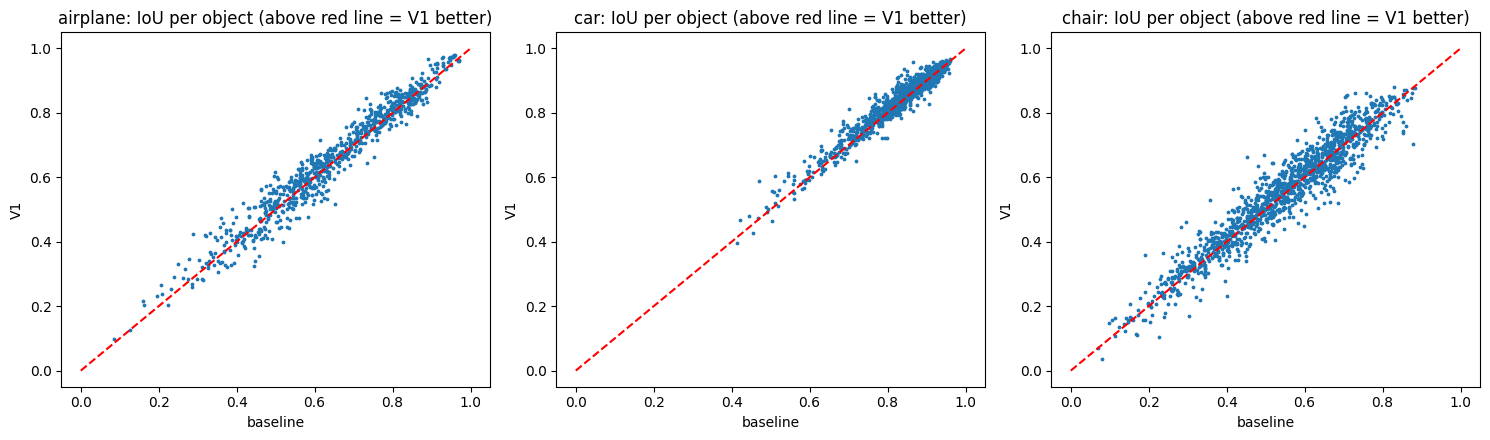

In [27]:
df_v1 = pd.read_csv("outputs/baseline2/v1_dinov2/analysis_test.csv")
compare = pd.DataFrame({"baseline": per_object, "v1": df_v1.groupby(["class", "object"])["iou_0.5"].mean()})
for name in ["airplane", "car", "chair"]:
    c = compare.loc[name]
    hard = c[c["baseline"] < c["baseline"].quantile(0.1)]
    print(name, "| objects improved:", round((c["v1"] > c["baseline"]).mean() * 100, 1), "%",
          "| hardest 10% for baseline: IoU", round(hard["baseline"].mean(), 3), "->", round(hard["v1"].mean(), 3))
print(df_v1.groupby("class")[["iou_0.5", "precision", "recall", "pred_voxels"]].mean().round(3))
df_v1["size_quartile"] = df_v1.groupby("class")["gt_voxels"].transform(lambda s: pd.qcut(s, 4, labels=False))
print(df_v1.pivot_table(index="class", columns="size_quartile", values="iou_0.5").round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, name in zip(ax, ["airplane", "car", "chair"]):
    c = compare.loc[name]
    a.scatter(c["baseline"], c["v1"], s=3)
    a.plot([0, 1], [0, 1], "r--")
    a.set_title(f"{name}: IoU per object (above red line = V1 better)")
    a.set_xlabel("baseline")
    a.set_ylabel("V1")
plt.tight_layout()
plt.show()

In [28]:
!python src/train_retr.py --config configs/retr_v2_queries.yaml

Training already finished, log:
Epoch 1/50  loss 0.6772  val IoU 0.5364  lr 1.0e-04  56s
Epoch 2/50  loss 0.6321  val IoU 0.5595  lr 1.0e-04  57s
Epoch 3/50  loss 0.6226  val IoU 0.5714  lr 1.0e-04  56s
Epoch 4/50  loss 0.6159  val IoU 0.5888  lr 1.0e-04  57s
Epoch 5/50  loss 0.6115  val IoU 0.5948  lr 1.0e-04  56s
Epoch 6/50  loss 0.6084  val IoU 0.6144  lr 1.0e-04  56s
Epoch 7/50  loss 0.6058  val IoU 0.6169  lr 1.0e-04  56s
Epoch 8/50  loss 0.6039  val IoU 0.6171  lr 1.0e-04  56s
Epoch 9/50  loss 0.6012  val IoU 0.6256  lr 1.0e-04  56s
Epoch 10/50  loss 0.5996  val IoU 0.6203  lr 1.0e-04  57s
Epoch 11/50  loss 0.5979  val IoU 0.6336  lr 1.0e-04  56s
Epoch 12/50  loss 0.5967  val IoU 0.6305  lr 1.0e-04  57s
Epoch 13/50  loss 0.5954  val IoU 0.6388  lr 1.0e-04  56s
Epoch 14/50  loss 0.5937  val IoU 0.6435  lr 1.0e-04  57s
Epoch 15/50  loss 0.5928  val IoU 0.6412  lr 1.0e-04  57s
Epoch 16/50  loss 0.5917  val IoU 0.6421  lr 1.0e-04  57s
Epoch 17/50  loss 0.5904  val IoU 0.6456  lr 1.0e

In [29]:
!python src/evaluate_retr.py --config configs/retr_v2_queries.yaml --ckpt outputs/baseline2/v2_queries/best.pt --name test_full

Checkpoint epoch: 49
[test] objects: 3668, samples: 3668, skipped (missing files): 0
class          IoU
airplane    0.6540
car         0.8502
chair       0.5534
mean        0.6859
Params: 26.34M
Inference: 17.8 ms/image, GPU memory 0.18 GB


In [30]:
!python src/train_retr.py --config configs/retr_v3_cosine.yaml

Training already finished, log:
Epoch 1/50  loss 0.6762  val IoU 0.5128  lr 1.0e-04  81s
Epoch 2/50  loss 0.6354  val IoU 0.5429  lr 1.0e-04  81s
Epoch 3/50  loss 0.6247  val IoU 0.5629  lr 9.9e-05  82s
Epoch 4/50  loss 0.6171  val IoU 0.5945  lr 9.8e-05  81s
Epoch 5/50  loss 0.6121  val IoU 0.6078  lr 9.8e-05  81s
Epoch 6/50  loss 0.6091  val IoU 0.6140  lr 9.6e-05  81s
Epoch 7/50  loss 0.6060  val IoU 0.6183  lr 9.5e-05  82s
Epoch 8/50  loss 0.6039  val IoU 0.6216  lr 9.4e-05  82s
Epoch 9/50  loss 0.6011  val IoU 0.6266  lr 9.2e-05  82s
Epoch 10/50  loss 0.5998  val IoU 0.6186  lr 9.0e-05  81s
Epoch 11/50  loss 0.5980  val IoU 0.6296  lr 8.9e-05  81s
Epoch 12/50  loss 0.5963  val IoU 0.6317  lr 8.6e-05  81s
Epoch 13/50  loss 0.5952  val IoU 0.6397  lr 8.4e-05  82s
Epoch 14/50  loss 0.5936  val IoU 0.6424  lr 8.2e-05  82s
Epoch 15/50  loss 0.5919  val IoU 0.6459  lr 7.9e-05  82s
Epoch 16/50  loss 0.5910  val IoU 0.6446  lr 7.7e-05  82s
Epoch 17/50  loss 0.5897  val IoU 0.6493  lr 7.4e

In [31]:
!python src/evaluate_retr.py --config configs/retr_v3_cosine.yaml --ckpt outputs/baseline2/v3_cosine/best.pt --name test_full

Checkpoint epoch: 50
[test] objects: 3668, samples: 3668, skipped (missing files): 0
class          IoU
airplane    0.6597
car         0.8533
chair       0.5617
mean        0.6915
Params: 26.52M
Inference: 18.4 ms/image, GPU memory 0.18 GB


In [32]:
!python src/train_retr.py --config configs/retr_v4_augment.yaml

Training already finished, log:
Epoch 1/50  loss 0.6761  val IoU 0.4886  lr 1.0e-04  78s
Epoch 2/50  loss 0.6372  val IoU 0.5526  lr 1.0e-04  81s
Epoch 3/50  loss 0.6278  val IoU 0.5515  lr 9.9e-05  82s
Epoch 4/50  loss 0.6215  val IoU 0.5759  lr 9.8e-05  80s
Epoch 5/50  loss 0.6175  val IoU 0.5891  lr 9.8e-05  82s
Epoch 6/50  loss 0.6143  val IoU 0.5922  lr 9.6e-05  79s
Epoch 7/50  loss 0.6119  val IoU 0.5988  lr 9.5e-05  82s
Epoch 8/50  loss 0.6098  val IoU 0.6035  lr 9.4e-05  82s
Epoch 9/50  loss 0.6081  val IoU 0.5997  lr 9.2e-05  82s
Epoch 10/50  loss 0.6064  val IoU 0.5914  lr 9.0e-05  82s
Epoch 11/50  loss 0.6044  val IoU 0.6106  lr 8.9e-05  82s
Epoch 12/50  loss 0.6036  val IoU 0.6136  lr 8.6e-05  82s
Epoch 13/50  loss 0.6015  val IoU 0.6187  lr 8.4e-05  82s
Epoch 14/50  loss 0.6008  val IoU 0.6170  lr 8.2e-05  81s
Epoch 15/50  loss 0.5996  val IoU 0.6132  lr 7.9e-05  82s
Epoch 16/50  loss 0.5984  val IoU 0.6216  lr 7.7e-05  82s
Epoch 17/50  loss 0.5972  val IoU 0.6143  lr 7.4e

In [33]:
!python src/evaluate_retr.py --config configs/retr_v4_augment.yaml --ckpt outputs/baseline2/v4_augment/best.pt --name test_full

Checkpoint epoch: 50
[test] objects: 3668, samples: 3668, skipped (missing files): 0
class          IoU
airplane    0.6249
car         0.8324
chair       0.5356
mean        0.6643
Params: 26.52M
Inference: 18.0 ms/image, GPU memory 0.18 GB


In [34]:
!python src/eval_pix3d_retr.py --configs configs/retr_s.yaml configs/retr_v1_dinov2.yaml configs/retr_v2_queries.yaml configs/retr_v3_cosine.yaml configs/retr_v4_augment.yaml

Pix3D chair images: 2777
Chosen rotation (Pix3D -> ShapeNet axes):
 [[ 0. -1.  0.]
 [-1.  0.  0.]
 [ 0.  0. -1.]] 
mean CD to nearest ShapeNet chair: 7.833
Chosen axes (voxel -> point cloud):
 [[ 0. -1.  0.]
 [ 0.  0. -1.]
 [ 1.  0.  0.]] 
GT voxels vs GT points CD x100: 4.186
100% 44/44 [10:33<00:00, 14.40s/it]
retr_s Pix3D chair: CD x100 7.391  F@0.01 0.0709  IoU 0.2925
retr_v1_dinov2 Pix3D chair: CD x100 7.051  F@0.01 0.0760  IoU 0.3107
retr_v2_queries Pix3D chair: CD x100 7.365  F@0.01 0.0723  IoU 0.3024
retr_v3_cosine Pix3D chair: CD x100 7.249  F@0.01 0.0739  IoU 0.3041
retr_v4_augment Pix3D chair: CD x100 7.112  F@0.01 0.0747  IoU 0.3268


Chosen rotation (Pix3D -> ShapeNet axes):
 [[ 0. -1.  0.]
 [-1.  0.  0.]
 [ 0.  0. -1.]] 
mean CD to nearest ShapeNet chair: 7.833


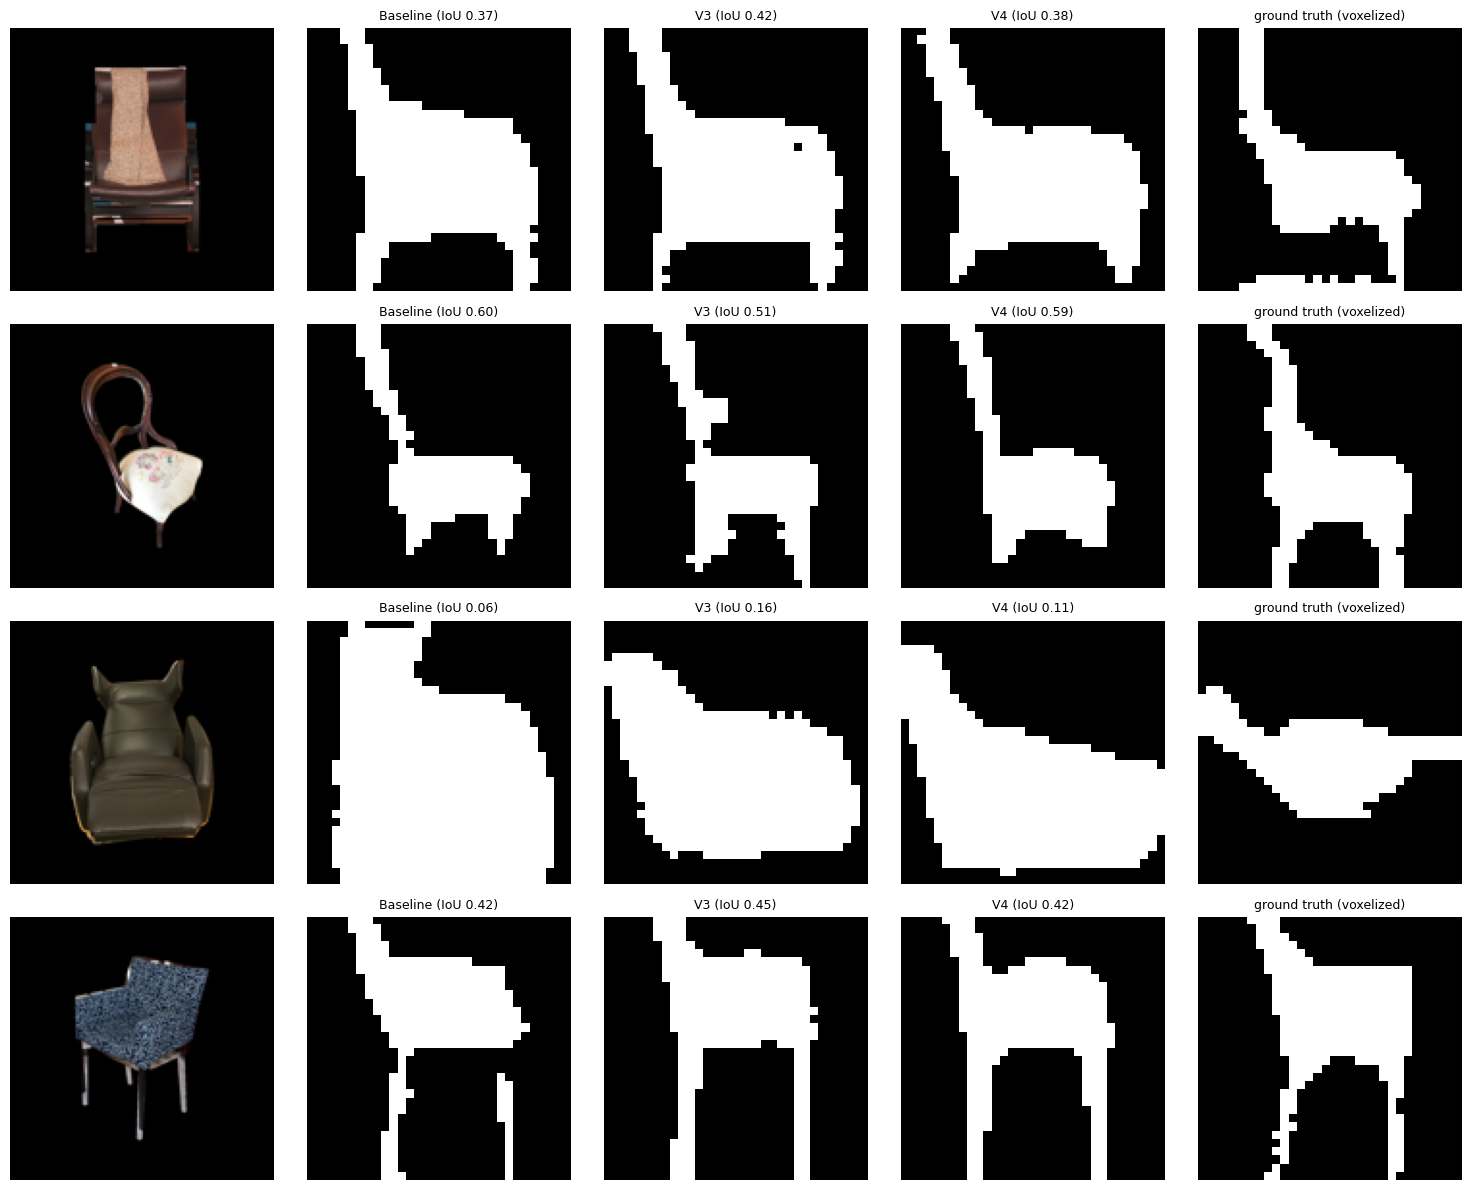

In [35]:
items = json.load(open("data/raw/pix3d/pix3d.json"))
items = [it for it in items if it["category"] == "chair" and not it["truncated"] and not it["occluded"]]
gt_file = lambda it: f"data/raw/pix3d_pointclouds/model/chair/{it['model'].split('/')[2]}/pcl_1024.npy"
items = [it for it in items if os.path.exists(gt_file(it))]
chosen = items[::700]

shapenet_chairs = load_points(cfg["data"], read_split("data/ShapeNet.json", ["chair"], "train")[:300]).cuda()
gt_files = sorted({gt_file(it) for it in items})
pix3d_chairs = torch.tensor(np.stack([np.load(f) for f in gt_files[:50]])).float().cuda()
rotation = choose_rotation(pix3d_chairs - pix3d_chairs.mean(1, keepdim=True), shapenet_chairs).float()

configs = {"Baseline": "configs/retr_s.yaml", "V3": "configs/retr_v3_cosine.yaml", "V4": "configs/retr_v4_augment.yaml"}
models = {label: (load_trained(load_config(path), "cuda"), retr_transform(load_config(path)["data"])) for label, path in configs.items()}

fig, ax = plt.subplots(len(chosen), 5, figsize=(15, 3 * len(chosen)))
for row, it in enumerate(chosen):
    image = load_image("data/raw/pix3d", it, (0, 0, 0)).resize((137, 137))
    gt_points = torch.tensor(np.load(gt_file(it))).float()
    gt_voxels = points_to_voxels((gt_points - gt_points.mean(0)) @ rotation.cpu().T, axes)
    ax[row, 0].imshow(image)
    columns = []
    for label, (m, transform) in models.items():
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
            voxels = (torch.sigmoid(m(transform(image)[None].cuda()).float()) > 0.5)[0].cpu()
        columns.append((f"{label} (IoU {((voxels & gt_voxels).sum() / (voxels | gt_voxels).sum()).item():.2f})", voxels))
    columns.append(("ground truth (voxelized)", gt_voxels))
    for col, (title, voxels) in enumerate(columns):
        ax[row, col + 1].imshow(voxels.amax(2).T.numpy(), origin="lower", cmap="gray")
        ax[row, col + 1].set_title(title, fontsize=9)
    for a in ax[row]:
        a.axis("off")
plt.tight_layout()
plt.show()

In [36]:
versions = {"Baseline": "base_retr_s", "V1 DINOv2": "v1_dinov2", "V2 512 queries": "v2_queries",
            "V3 cosine lr": "v3_cosine", "V4 augmentation": "v4_augment"}
rows = []
for label, folder in versions.items():
    r = json.load(open(f"outputs/baseline2/{folder}/test_full.json"))
    p = json.load(open(f"outputs/baseline2/{folder}/pix3d.json"))["chair"]
    rows.append([label] + [r[class_id]["iou"] for class_id in list(CLASS_NAMES) + ["mean"]]
                + [r["params_total"] / 1e6, r["time_ms"], p["iou"], p["cd"] * 100, p["fscore"]])
columns = ["model"] + [f"{name} IoU" for name in CLASS_NAMES.values()] + ["mean IoU", "params M", "ms/image",
                                                                        "Pix3D chair IoU", "Pix3D chair CD", "Pix3D chair F"]
pd.DataFrame(rows, columns=columns).round(3).T

,0,1,2,3,4
model,Baseline,V1 DINOv2,V2 512 queries,V3 cosine lr,V4 augmentation
airplane IoU,0.649,0.657,0.654,0.66,0.625
car IoU,0.841,0.85,0.85,0.853,0.832
chair IoU,0.543,0.552,0.553,0.562,0.536
mean IoU,0.678,0.686,0.686,0.692,0.664
params M,10.341,26.52,26.344,26.52,26.52
ms/image,16.993,18.255,17.787,18.41,17.968
Pix3D chair IoU,0.293,0.311,0.302,0.304,0.327
Pix3D chair CD,7.391,7.051,7.365,7.249,7.112
Pix3D chair F,0.071,0.076,0.072,0.074,0.075


In [37]:
!python src/cross_eval.py --retr_configs configs/retr_s.yaml configs/retr_v1_dinov2.yaml configs/retr_v2_queries.yaml configs/retr_v3_cosine.yaml configs/retr_v4_augment.yaml --rgb2point_configs configs/rgb2point.yaml configs/v0_no_attention.yaml configs/v1_query.yaml configs/v2_dinov2.yaml configs/v3_finetune.yaml

Chosen axes (voxel -> point cloud):
 [[ 0. -1.  0.]
 [ 0.  0. -1.]
 [ 1.  0.  0.]] 
GT voxels vs GT points CD x100: 3.853
Checkpoint epoch: 40
rgb2point {'cd': 0.0398, 'fscore': 0.2303, 'iou': 0.5054}
Checkpoint epoch: 38
v0_no_attention {'cd': 0.0402, 'fscore': 0.2314, 'iou': 0.5078}
Checkpoint epoch: 38
v1_query {'cd': 0.0375, 'fscore': 0.2453, 'iou': 0.5391}
Checkpoint epoch: 50
v2_dinov2 {'cd': 0.0347, 'fscore': 0.2739, 'iou': 0.5736}
Checkpoint epoch: 7
v3_finetune {'cd': 0.0342, 'fscore': 0.2734, 'iou': 0.5776}
[test] objects: 3668, samples: 3668, skipped (missing files): 0
retr_s {'cd': 0.0455, 'fscore': 0.1581, 'iou': 0.6775}
[test] objects: 3668, samples: 3668, skipped (missing files): 0
retr_v1_dinov2 {'cd': 0.0448, 'fscore': 0.16, 'iou': 0.6863}
[test] objects: 3668, samples: 3668, skipped (missing files): 0
retr_v2_queries {'cd': 0.0453, 'fscore': 0.159, 'iou': 0.6859}
[test] objects: 3668, samples: 3668, skipped (missing files): 0
retr_v3_cosine {'cd': 0.0456, 'fscore': 0.

In [38]:
cross = json.load(open("outputs/baseline2/cross_eval.json"))
rows = []
for model_name, r in cross.items():
    rows.append([model_name] + [r["iou"][k] for k in list(CLASS_NAMES) + ["mean"]]
                + [r["cd"][k] * 100 for k in list(CLASS_NAMES) + ["mean"]] + [r["fscore"]["mean"]])
columns = ["model"] + [f"{name} IoU" for name in list(CLASS_NAMES.values()) + ["mean"]] \
          + [f"{name} CD" for name in list(CLASS_NAMES.values()) + ["mean"]] + ["mean F@0.01"]
pd.DataFrame(rows, columns=columns).round(3)

,model,airplane IoU,car IoU,chair IoU,mean IoU,airplane CD,car CD,chair CD,mean CD,mean F@0.01
0,GT voxels / GT points,0.783,0.784,0.602,0.723,2.533,4.517,3.941,3.664,0.197
1,rgb2point,0.488,0.713,0.316,0.505,2.588,4.003,5.363,3.985,0.230
2,v0_no_attention,0.489,0.709,0.325,0.508,2.608,4.028,5.412,4.016,0.231
3,v1_query,0.519,0.727,0.371,0.539,2.495,3.856,4.906,3.752,0.245
4,v2_dinov2,0.566,0.743,0.411,0.574,2.282,3.694,4.424,3.467,0.274
5,v3_finetune,0.556,0.753,0.425,0.578,2.262,3.651,4.360,3.424,0.273
6,retr_s,0.649,0.841,0.543,0.678,3.144,4.879,5.633,4.552,0.158
7,retr_v1_dinov2,0.657,0.850,0.552,0.686,3.086,4.842,5.502,4.476,0.160
8,retr_v2_queries,0.654,0.850,0.553,0.686,3.154,4.827,5.607,4.530,0.159
9,retr_v3_cosine,0.660,0.853,0.562,0.692,3.163,4.860,5.653,4.559,0.157
